# 路线一 · 单被试有截止的证据积累模型

在正式实验的 Matching 任务中，比较 Gaussian 与 Lévy 对单被试选择和反应时的预测。两个模型共用八条件结构、作答窗口和留出试次。Gaussian 固定 α=2，Lévy 让每名被试单独估计 α。

**阅读顺序**　设置与数据 → 参数和模拟器 → BayesFlow 训练 → 参数恢复 → 真人留出预测。  
**运行目录**　`scripts/`。已有完整训练记录时，直接载入最后一轮检查点。CSV、PDF 和模型权重保存在[中档结果目录](../outputs/levy/individual_window_recovery_optimization/)。小档的两份参数恢复表用于预算对照。

单元格下方展示已保存的中档运行结果。重新执行时会载入检查点并保存当次复算结果。

## 1. 运行设置和有效试次

### 1.1 路径、训练预算和抽样数

每轮 500 批，每批 32 名模拟被试，共 30 轮、15,000 次更新。数值步长来自[层级版数值检查](../README.md#数值步长)，用于两种噪声模型。

In [1]:
import os
from pathlib import Path
from io import BytesIO
from time import perf_counter

# Keras 在首次导入时读取后端设置。
os.environ["KERAS_BACKEND"] = "jax"
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import bayesflow as bf
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from numba import njit, prange
from scipy.special import expit, gammaincinv, gammainccinv, logit, logsumexp, ndtr
from scipy.stats import gamma, truncnorm

# 路径相对于 scripts 目录。小档结果用于后面的配对恢复比较。
data_dir = Path("../../01_reproduction_2020/data")
outputs = Path("../outputs/levy/individual_window_recovery_optimization")
pilot_dir = Path("../outputs/levy/individual_window_flow_check")
outputs.mkdir(parents=True, exist_ok=True)

# 试次划分、模拟精度和训练预算。
seed = 2026
dt = 3.125e-5
batch_size, steps_per_epoch, epochs = 32, 500, 30
n_validation, simulation_chunk_batches = 512, 20

# 独立参数恢复和真人留出预测的模拟数量。
n_recovery, recovery_batch_size, recovery_draws = 128, 32, 256
empirical_draws, predictive_draws = 512, 100
models = {"Gaussian": 0, "Levy": 1}
keras.utils.set_random_seed(seed)

def save_table(table, name):
    """把当前统计表写入本路线的输出目录。"""
    table.to_csv(outputs / f"{name}.csv", index=False)

def show_figure(fig, name):
    """保存 PDF，在 Notebook 中显示同一张图，然后释放图对象。"""
    fig.tight_layout()
    fig.savefig(outputs / f"{name}.pdf", bbox_inches="tight")
    image = BytesIO()
    fig.savefig(image, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=image.getvalue()))
    plt.close(fig)

INFO:bayesflow:Using backend 'jax'


/home/dean_tang/miniconda3/envs/hu-bayesflow-jax/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 划分拟合与留出试次

按每名被试的八个刺激条件分层，沿用第二部分 M2 的 20% 留出方案。以每人超时记录的 RT 中位数估计作答窗口。有效作答包括按了有效键的正确和错误试次。

In [2]:
# 用正式实验原始按键核对第一部分的试次编码和 RT，保留其纳入的被试。
trials = pd.read_csv(data_dir / "derived/matching_hddm.csv")
subjects = pd.Index(sorted(trials["subj_idx"].unique()), name="subj_idx")
raw = pd.read_csv(data_dir / "raw/MS_rep_matchingTask_raw.csv")
raw = raw.loc[raw["Prac"].eq("Exp") & raw["Subject"].isin(subjects)]
model_columns = ["subj_idx", "match", "val", "id", "stim", "response", "rt"]
raw_to_model = {
    "Subject": "subj_idx", "Match": "match", "Morality": "val", "Identity": "id", "RT": "rt",
}
valid = raw.loc[raw["ACC"].isin([0, 1])].rename(columns=raw_to_model)
valid["stim"] = valid["match"].eq("match").astype(int)
# 答对时按键等于刺激类别，答错时按下另一侧。
valid["response"] = np.where(valid["ACC"].eq(1), valid["stim"], 1 - valid["stim"])
pd.testing.assert_frame_equal(
    valid[model_columns].sort_values(model_columns, ignore_index=True),
    trials[model_columns].sort_values(model_columns, ignore_index=True),
    check_dtype=False,
)

# 每人超时记录的 RT 中位数近似其截止时刻，单位为秒。
timeout_trials = raw.loc[raw["ACC"].eq(-1)]
deadline = timeout_trials.groupby("Subject")["RT"].median().reindex(subjects)
window_counts = pd.DataFrame({
    "deadline_s": deadline,
    "scheduled": raw.groupby("Subject").size(),
    "timeout": raw["ACC"].eq(-1).groupby(raw["Subject"]).sum(),
    "invalid_key": raw["ACC"].eq(2).groupby(raw["Subject"]).sum(),
    "valid": trials.groupby("subj_idx").size(),
}).rename_axis("subj_idx").reset_index()
trial_deadlines = trials["subj_idx"].map(deadline)
assert deadline.notna().all()
assert trials["rt"].between(0, trial_deadlines, inclusive="right").all()
save_table(window_counts, "response_windows")

# 与第二部分相同，在各被试、匹配状态、效价、身份内留出 20%。
trial_columns = ["match", "val", "id"]
heldout_index = (
    trials.groupby(["subj_idx", *trial_columns]).sample(frac=0.2, random_state=seed).index
)
trials["shape"] = trials["val"] + "-" + trials["id"].str.lower()
trials["condition"] = trials["match"] + "_" + trials["shape"]
training_trials = trials.drop(index=heldout_index).reset_index(drop=True)
heldout_trials = trials.loc[heldout_index].reset_index(drop=True)
# 汇总有效按键、超时、异常按键及拟合和留出试次数。
display(
    window_counts.agg({"valid": "sum", "timeout": "sum", "invalid_key": "sum"}),
    pd.Series({
        "participants": len(subjects), "fit": len(training_trials), "held_out": len(heldout_trials),
        "min_deadline_s": deadline.min(), "max_deadline_s": deadline.max(),
    }),
)

valid          24528
timeout          649
invalid_key       23
dtype: int64

participants         42.0000
fit               19599.0000
held_out           4929.0000
min_deadline_s        1.0170
max_deadline_s        1.1831
dtype: float64

### 1.3 八个刺激条件和实际选择

四种形状分别与实际匹配、不匹配交叉。刺激状态标明正确按键方向。有符号 RT 的正负表示实际按键，正为 Match，负为 Non-match。

In [3]:
# 四种形状与两种实际匹配状态交叉，形成八个刺激条件。
shapes = pd.Index(["Good-self", "Bad-self", "Good-other", "Bad-other"])
conditions = pd.Index([f"{match}_{shape}" for match in ("match", "mismatch") for shape in shapes])
design = training_trials.drop_duplicates("condition").set_index("condition").loc[conditions]
# 实际匹配刺激给正漂移方向。同一形状在两种刺激方向上共用起点。
stim_sign = 2 * design["stim"].to_numpy() - 1
shape_index = shapes.get_indexer(design["shape"])

def trial_grid(rows):
    """按被试和试次位置填写条件编号，并返回每行数据在网格中的位置。"""
    person = subjects.get_indexer(rows["subj_idx"])
    position = rows.groupby("subj_idx").cumcount().to_numpy()
    # 每人有效试次数可不同，末尾填上 −1 的位置会被模拟器跳过。
    grid = np.full((len(subjects), position.max() + 1), -1, dtype=np.int32)
    grid[person, position] = conditions.get_indexer(rows["condition"])
    return grid, (person, position)

fit_grid, fit_slots = trial_grid(training_trials)
test_grid, test_slots = trial_grid(heldout_trials)
# 用正负号保存实际选择，绝对值保存秒数。Match 为正，Non-match 为负。
choice_sign = 2 * training_trials["response"] - 1
observed_rt = np.zeros(fit_grid.shape, dtype=np.float32)
observed_rt[fit_slots] = training_trials["rt"] * choice_sign

# 每份网络输入保留八个条件的实际试次数，以及该被试的作答截止时间。
condition_counts = (fit_grid[..., None] == np.arange(len(conditions))).sum(axis=1)
assert (condition_counts > 0).all()
deadlines = deadline.to_numpy(dtype=np.float64)
display(design[["match", "shape", "stim"]])

,match,shape,stim
condition,,,
match_Good-self,match,Good-self,1
match_Bad-self,match,Bad-self,1
match_Good-other,match,Good-other,1
match_Bad-other,match,Bad-other,1
mismatch_Good-self,mismatch,Good-self,0
mismatch_Bad-self,mismatch,Bad-self,0
mismatch_Good-other,mismatch,Good-other,0
mismatch_Bad-other,mismatch,Bad-other,0


## 2. 个人参数和先验

每人保留八个漂移率 v、一个全边界间距 a、四个起点比例 z、八个非决策时间 t。以层级版路线一的先验为单人的生成依据。先抽取一套组层位置和个体差异尺度，再生成一个人的参数，相当于对单人的组层变量取边际。训练与真人推断均按人独立。Lévy 的 α 继续使用 Liss 的截断正态先验。Gaussian 的同一网络坐标仅用于保持形状一致，其模拟始终固定 α=2。[先验来源](https://github.com/jvliss/time_to_jump/blob/01ee42cf72736de2800b64c846d7d9fdb5e73f6b/3_simulators/functions_param_estim.py#L13-L53)

In [4]:
# 抽取一名新个体时，先生成组层位置与标准差，再生成个人参数。
v_cols = slice(0, len(conditions))
a_col = v_cols.stop
z_cols = slice(a_col + 1, a_col + 1 + len(shapes))
t_cols = slice(z_cols.stop, z_cols.stop + len(conditions))
n_local = t_cols.stop
sd_cols = slice(n_local, n_local + 4)
n_group = sd_cols.stop + 1

# SciPy 的截断正态要求用标准差为单位指定上下界，α 在原尺度上介于 1 与 2。
alpha_prior = truncnorm((1 - 1.55) / 0.29, (2 - 1.55) / 0.29, loc=1.55, scale=0.29)

def unit_gamma(score, shape):
    """把标准正态分位映射到单位尺度 Gamma 分布的同一分位。"""
    score = np.asarray(score, dtype=np.float64)
    # 右尾用生存概率计算，以免累积概率被舍入为 1。
    lower_quantile = gammaincinv(shape, ndtr(score))
    upper_quantile = gammainccinv(shape, ndtr(-score))
    return np.where(score <= 0, lower_quantile, upper_quantile)

def group_parameters(group):
    """把一组标准正态坐标还原为 M2 的组层位置与四个被试间标准差。"""
    v = 2 + 3 * group[..., v_cols]
    a = 0.375 * unit_gamma(group[..., a_col:a_col + 1], 4)
    logit_z = 0.5 * group[..., z_cols]
    t = 0.1 * unit_gamma(group[..., t_cols], 4)
    # 四个半正态先验的尺度依次对应 v、a、logit(z)、t。
    halfnormal_scales = np.array([2, 2, 0.05, 1])
    sd = halfnormal_scales * np.sqrt(2 * unit_gamma(group[..., sd_cols], 0.5))
    return v, a, logit_z, t, sd

# 在 Liss 的参考先验中取中央 99.9%，作为个体 a 和 t 的共同取值范围。
tail = np.array([0.0005, 0.9995])
a_limits = gamma.ppf(tail, a=4, scale=0.25)
t_limits = truncnorm.ppf(tail, (0.1 - 0.25) / 0.1, (1 - 0.25) / 0.1, loc=0.25, scale=0.1)

def bounded_lognormal(score, mean, sd, limits):
    """按组层给定的均值和标准差构造对数正态，再在个体参数范围内取分位数。"""
    log_sd = np.sqrt(np.log1p((sd / mean) ** 2))
    log_mean = np.log(mean) - log_sd**2 / 2
    lower = (np.log(limits[0]) - log_mean) / log_sd
    upper = (np.log(limits[1]) - log_mean) / log_sd
    # 正分位在反射后的左尾计算，避免右尾概率舍入到 1。
    tail_probability = ndtr(-np.abs(np.asarray(score, dtype=float)))
    left_quantile = truncnorm.ppf(tail_probability, lower, upper)
    right_quantile = -truncnorm.ppf(tail_probability, -upper, -lower)
    normal_quantile = np.where(score <= 0, left_quantile, right_quantile)
    return np.exp(log_mean + log_sd * normal_quantile)

def person_parameters(group, local):
    """将组层位置和个人偏移组合为八个 v、一个 a、四个 z、八个 t。"""
    v, a, logit_z, t, sd = group_parameters(group)
    sd_v, sd_a, sd_z, sd_t = np.split(sd, 4, axis=-1)
    person_v = v + sd_v * local[..., v_cols]
    person_a = bounded_lognormal(local[..., a_col:a_col + 1], a, sd_a, a_limits)
    # expit 将起点从 logit 尺度转回两条边界之间的比例。
    person_z = expit(logit_z + sd_z * local[..., z_cols])
    person_t = bounded_lognormal(local[..., t_cols], t, sd_t, t_limits)
    return np.concatenate([person_v, person_a, person_z, person_t], axis=-1)

n_parameters = n_local + 1

def sample_prior_scores(size, rng):
    """抽取互相独立的个人先验样本，并将有界参数换到无界坐标。"""
    group = rng.standard_normal((size, n_group))
    local = rng.standard_normal((size, n_local))
    natural = person_parameters(group, local)

    v_score = (natural[:, v_cols] - 2) / np.sqrt(13)
    a = natural[:, a_col:a_col + 1]
    a_proportion = (a - a_limits[0]) / np.diff(a_limits)[0]
    t = natural[:, t_cols]
    t_proportion = (t - t_limits[0]) / np.diff(t_limits)[0]
    # 1e−7 只用于避免正好落到浮点端点时 logit 为无穷。
    a_score = logit(np.clip(a_proportion, 1e-7, 1 - 1e-7)) / 2
    t_score = logit(np.clip(t_proportion, 1e-7, 1 - 1e-7)) / 2
    z_score = logit(natural[:, z_cols]) / 0.5
    alpha_score = group[:, -1:]
    return np.concatenate([v_score, a_score, z_score, t_score, alpha_score], axis=-1).astype("float32")

def individual_parameters(scores, model_code):
    """将个人后验抽样转换为 v、a、z、t 和物理 α，保留输入的批量维度。"""
    v = 2 + np.sqrt(13) * scores[..., v_cols]
    a = a_limits[0] + np.diff(a_limits)[0] * expit(2 * scores[..., a_col:a_col + 1])
    z = expit(0.5 * scores[..., z_cols])
    t = t_limits[0] + np.diff(t_limits)[0] * expit(2 * scores[..., t_cols])
    alpha = alpha_prior.ppf(ndtr(scores[..., -1:].astype(np.float64)))
    alpha = np.where(model_code == 1, alpha, 2.0)
    return np.concatenate([v, a, z, t, alpha], axis=-1)

display(pd.DataFrame([a_limits, t_limits], index=["a", "t (s)"], columns=["lower", "upper"]))


,lower,upper
a,0.088797,3.483506
t (s),0.100359,0.580993


## 3. 首达时间模拟

从 az 起步，每步加上刺激方向的漂移及 Gaussian 或 Lévy 噪声。首个越界给出选择与 RT，其中 RT 包含非决策时间。超过个人窗口便用相同参数重抽路径，从而生成在窗口内作答时的选择与 RT。每名模拟被试随机取一个真人试次设计与其窗口。

In [5]:
@njit(parallel=True)
def simulate_signed_rt(parameters, grid, seeds, deadlines, dt):
    """按被试和刺激条件模拟首次越界的带符号 RT，单位为秒。"""
    n_people = len(parameters)
    result = np.zeros(grid.shape, dtype=np.float32)

    # 每个并行任务是一名模拟被试，使用独立随机种子和一个 α。
    for person_id in prange(n_people):
        np.random.seed(seeds[person_id])
        person = parameters[person_id]
        alpha = person[-1]
        boundary = person[a_col]
        deadline_s = deadlines[person_id]
        levy_scale = dt ** (1 / alpha) / np.sqrt(2)

        for trial, condition in enumerate(grid[person_id]):
            if condition < 0:  # 网格尾部的填充位置。
                break
            # 漂移朝向由刺激指定，起点由形状指定，非决策时间按刺激条件取值。
            drift = stim_sign[condition] * person[condition]
            relative_start = person[z_cols.start + shape_index[condition]]
            start = boundary * relative_start
            nondecision_time = person[t_cols.start + condition]
            evidence, step = start, 0

            while True:
                step += 1
                rt = nondecision_time + step * dt
                if rt > deadline_s:
                    # 在同一参数下重抽路径，得到该人在窗口内作答的条件分布。
                    evidence, step = start, 0
                    continue

                if alpha == 2:
                    noise = np.sqrt(dt) * np.random.standard_normal()
                else:
                    # 两个辅助随机数生成一次对称稳定增量，允许证据向任一方向跳跃。
                    noise_angle = np.random.uniform(-np.pi / 2, np.pi / 2)
                    exponential_draw = np.random.exponential()
                    angular_term = (
                        levy_scale * np.sin(alpha * noise_angle) / np.cos(noise_angle) ** (1 / alpha)
                    )
                    tail_term = (
                        np.cos((1 - alpha) * noise_angle) / exponential_draw
                    ) ** ((1 - alpha) / alpha)
                    noise = angular_term * tail_term

                evidence += drift * dt + noise
                if evidence <= 0 or evidence >= boundary:
                    # 上界为 Match（+RT），下界为 Non-match（−RT）。
                    result[person_id, trial] = rt if evidence >= boundary else -rt
                    break
    return result

assert t_limits[1] + dt < deadlines.min()

def simulation_inputs(model_codes, rng):
    """抽取单被试设计、先验参数和证据路径所需的随机种子。"""
    size = len(model_codes)
    labels = np.asarray(model_codes, dtype=np.float32).reshape(size, 1)
    scores = sample_prior_scores(size, rng)
    design_ids = rng.integers(len(subjects), size=size, dtype=np.int32)
    seeds = rng.integers(2**32, size=size, dtype=np.uint32)
    return {
        "condition": fit_grid[design_ids], "deadline": deadlines[design_ids, None].astype("float32"),
        "parameters": scores, "model_code": labels, "design_id": design_ids,
        "seeds": seeds,
    }

def simulate_inputs(inputs):
    """按输入设计生成有符号 RT。物理窗口使用原始的双精度秒数。"""
    parameters = individual_parameters(inputs["parameters"], inputs["model_code"])
    signed_rt = simulate_signed_rt(
        parameters, inputs["condition"], inputs["seeds"], deadlines[inputs["design_id"]], dt,
    )
    return {"signed_rt": signed_rt, **{key: value for key, value in inputs.items() if key != "seeds"}}

def simulate_batch(model_codes, rng):
    """生成独立参数恢复检验需要的一批被试和对应真值。"""
    return simulate_inputs(simulation_inputs(model_codes, rng))

## 4. BayesFlow 训练

### 4.1 按轮模拟和独立验证集

每轮独立生成 16,000 份模拟作答，每批 Gaussian 与 Lévy 各 16 人。CPU 合并 20 批运行模拟，网络仍按每批 32 人更新。固定验证集另有 512 份，和小档逐条一致。

In [6]:
batch_dir = outputs / "simulation_batches"
batch_dir.mkdir(exist_ok=True)
training_files = [batch_dir / f"epoch_{epoch:02d}.npz" for epoch in range(1, epochs + 1)]
validation_file = batch_dir / "validation.npz"
seed_sequences = np.random.SeedSequence(seed + 10).spawn(epochs + 1)

def write_simulation_file(path, n_batches, simulation_seed):
    """独立生成一轮数据。每个训练批中两种模型各 16 人。"""
    rng = np.random.default_rng(simulation_seed)
    balanced_codes = np.arange(batch_size) % 2
    chunks = []
    for start in range(0, n_batches, simulation_chunk_batches):
        stop = min(start + simulation_chunk_batches, n_batches)
        batches = [simulation_inputs(rng.permutation(balanced_codes), rng) for _ in range(start, stop)]
        inputs = {key: np.concatenate([batch[key] for batch in batches]) for key in batches[0]}
        chunks.append(simulate_inputs(inputs))
        if stop == n_batches or stop % 100 == 0:
            print(f"{path.stem} · 已模拟 {stop}/{n_batches} 批", flush=True)
    data = {key: np.concatenate([chunk[key] for chunk in chunks]) for key in chunks[0]}

    # 填充位为零，所有有效反应都须在该被试的作答窗口内。
    valid = data["condition"] >= 0
    assert np.array_equal(data["signed_rt"] != 0, valid)
    assert np.all(np.abs(data["signed_rt"]) <= data["deadline"] + 1e-7)
    temporary = path.with_suffix(".building.npz")
    np.savez(temporary, **data)
    temporary.replace(path)

if not validation_file.exists():
    write_simulation_file(validation_file, n_validation // batch_size, seed_sequences[0])
save_table(pd.DataFrame([{
    "batch_size": batch_size, "steps_per_epoch": steps_per_epoch, "epochs": epochs, "network_members": 1,
    "n_validation": n_validation, "seed": seed, "dt_s": dt,
}]), "training_settings")

### 4.2 单被试后验与模型辨别

每份输入包含一名被试的拟合试次。网络按八种条件汇总选择和 RT，并读取各条件的有效试次数和个人截止秒数。同一个网络用于所有被试。后验流按指定的噪声模型估计个人参数，分类器从作答摘要估计两个模型的概率。Gaussian 的第 22 个坐标是训练用辅助变量，模拟与预测中的 α 取 2。

In [7]:
class IndividualPosterior(bf.estimators.Estimator):
    """以一名被试的条件设计和有符号 RT 估计个人后验。"""

    def __init__(self):
        super().__init__()
        self.n_conditions = len(conditions)
        self.trial_width = 20
        self.summary_width = self.n_conditions * (self.trial_width + 1) + 1
        self.trial_encoder = keras.Sequential([
            keras.layers.Dense(32, activation="elu"),
            keras.layers.Dense(self.trial_width, activation="elu"),
        ])
        self.flow = bf.BasicEstimator(
            inference_network=bf.networks.CouplingFlow(depth=9, transform="spline"),
            standardize=None,
        )
        self.classifier = bf.estimators.ModelComparisonEstimator(
            inference_network=bf.networks.ScoringRuleNetwork(
                scoring_rules={"ce": bf.scoring_rules.CrossEntropyScore()},
            ),
            standardize=None,
        )

    def build(self, data_shapes):
        self.trial_encoder.build((None, None, 2))
        self.flow.build({
            "inference_variables": (1, n_parameters),
            "inference_conditions": (1, self.summary_width + 1),
        })
        self.classifier.build({
            "inference_variables": (1, 2),
            "inference_conditions": (1, self.summary_width),
        })
        self.built = True

    def _batch_size_from_data(self, data):
        return keras.ops.shape(data["signed_rt"])[0]

    def encode(self, signed_rt, condition, deadline, training=False):
        ops = keras.ops
        # 拆开实际按键和 RT。填充行的条件号为 −1，汇总时权重为零。
        trial_data = ops.stack([ops.sign(signed_rt), ops.log1p(ops.abs(signed_rt))], axis=-1)
        features = self.trial_encoder(trial_data, training=training)
        cell_mask = ops.one_hot(ops.cast(ops.maximum(condition, 0), "int32"), self.n_conditions, dtype="float32")
        cell_mask = cell_mask * ops.cast(condition[..., None] >= 0, "float32")
        counts = ops.sum(cell_mask, axis=1)
        sums = ops.einsum("btc,btf->bcf", cell_mask, features)
        cell_means = sums / counts[..., None]
        pooled = ops.reshape(cell_means, (-1, self.n_conditions * self.trial_width))
        return ops.concatenate([pooled, ops.log1p(counts), deadline], axis=-1)

    def compute_metrics(self, signed_rt, condition, deadline, parameters, model_code, stage="training"):
        ops = keras.ops
        summary = self.encode(signed_rt, condition, deadline, training=(stage == "training"))
        # 后验流读取噪声模型标签，分类器只读作答摘要。
        context = ops.concatenate([summary, model_code], axis=-1)
        posterior_loss = self.flow.compute_metrics(
            inference_variables=parameters, inference_conditions=context, stage=stage,
        )["loss"]
        targets = ops.concatenate([1 - model_code, model_code], axis=-1)
        classification_loss = self.classifier.compute_metrics(
            inference_variables=targets, inference_conditions=summary, stage=stage,
        )["loss"]
        return {
            "loss": posterior_loss + classification_loss,
            "posterior_loss": posterior_loss,
            "classification_loss": classification_loss,
        }

    def posterior(self, signed_rt, condition, deadline, model_code, n_draws, sample_seed):
        """返回每名被试在指定模型下的个人坐标抽样。"""
        summary = np.asarray(self.encode(signed_rt, condition, deadline))
        label = np.asarray(model_code, dtype="float32").reshape(-1, 1)
        label = np.broadcast_to(label, (len(summary), 1))
        context = np.concatenate([summary, label], axis=-1)
        result = self.flow.sample(
            num_samples=n_draws,
            conditions={"inference_conditions": context},
            seed=int(sample_seed),
        )
        return np.asarray(result["inference_variables"])

    def model_probabilities(self, signed_rt, condition, deadline):
        """按 Gaussian、Lévy 的顺序返回个人模型概率。"""
        summary = np.asarray(self.encode(signed_rt, condition, deadline))
        result = self.classifier.estimate(conditions={"inference_conditions": summary})
        return np.asarray(result["model_probs"])

### 4.3 逐轮训练、检查点与损失曲线

先生成一轮数据，再连续更新同一网络和 Adam 优化器。每轮保存权重和训练记录。运行中断后，使用最后一个完整轮次的权重与 Adam 状态续跑。训练和验证损失衡量网络的学习情况。

已载入第 30/30 轮检查点（15,000 次更新）


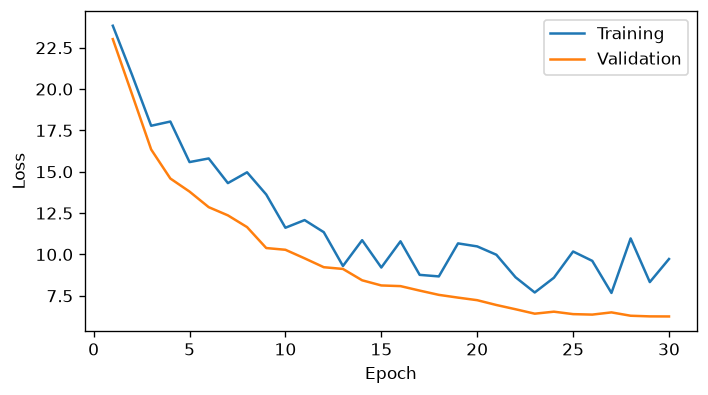

In [8]:
def load_simulations(path):
    """读取一轮模拟数据，挑选网络使用的字段。"""
    with np.load(path) as archive:
        arrays = {name: archive[name] for name in archive.files if name != "design_id"}
    return bf.datasets.OfflineDataset(arrays, batch_size=batch_size, adapter=None, shuffle=False)


validation_data = load_simulations(validation_file)
keras.utils.set_random_seed(seed + 21)
net = IndividualPosterior()
net.build(None)
schedule = keras.optimizers.schedules.CosineDecay(0.0001, epochs * steps_per_epoch)
net.compile(optimizer=keras.optimizers.Adam(schedule), jit_compile=True)

checkpoint_dir = outputs / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)
history_path = outputs / "training_history.csv"
history_rows = pd.read_csv(history_path).to_dict("records") if history_path.exists() else []
completed_epochs = len(history_rows)
if completed_epochs:
    # 权重文件同时保留 Adam 的变量。先建立优化器变量再载入。
    net.optimizer.build(net.trainable_variables)
    checkpoint = checkpoint_dir / f"epoch_{completed_epochs:02d}.weights.h5"
    net.load_weights(checkpoint)
    assert int(np.asarray(net.optimizer.iterations)) == completed_epochs * steps_per_epoch
    print(f"已载入第 {completed_epochs}/{epochs} 轮检查点（{completed_epochs * steps_per_epoch:,} 次更新）")

for epoch in range(completed_epochs, epochs):
    path = training_files[epoch]
    started = perf_counter()
    if not path.exists():
        write_simulation_file(path, steps_per_epoch, seed_sequences[epoch + 1])
    simulation_seconds = perf_counter() - started
    training_data = load_simulations(path)
    result = net.fit(
        dataset=training_data, validation_data=validation_data,
        initial_epoch=epoch, epochs=epoch + 1, verbose=2, shuffle=False,
    )
    updates = int(np.asarray(net.optimizer.iterations))
    assert updates == (epoch + 1) * steps_per_epoch
    history_rows.append({
        "epoch": epoch + 1, "optimizer_updates": updates, "simulation_seconds": simulation_seconds,
        **{name: values[-1] for name, values in result.history.items()},
    })
    # 先保存该轮模型，再提交训练记录。下一轮以记录最后一行为断点。
    net.save_weights(checkpoint_dir / f"epoch_{epoch + 1:02d}.weights.h5")
    temporary_history = history_path.with_suffix(".tmp")
    pd.DataFrame(history_rows).to_csv(temporary_history, index=False)
    temporary_history.replace(history_path)
    del training_data

training_history = pd.DataFrame(history_rows)
net.save_weights(outputs / "individual_posterior.weights.h5")

figure, axis = plt.subplots(figsize=(6, 3.4))
axis.plot(training_history["epoch"], training_history["loss"], label="Training")
axis.plot(training_history["epoch"], training_history["val_loss"], label="Validation")
axis.set(xlabel="Epoch", ylabel="Loss")
axis.legend()
show_figure(figure, "training_loss")

## 5. 独立模拟的参数恢复

### 5.1 对照已知参数、后验区间和先验基准

每个模型用 128 份独立模拟检查参数恢复。比较后验均值和模拟真值，同时报告仅猜先验均值的误差。95% 区间要结合覆盖率和宽度一起看。

In [9]:
# 按模拟器的参数顺序命名。两项差值始终在同一个被试、同一次抽样内计算。
parameter_names = [
    *[f"v:{condition}" for condition in conditions], "a",
    *[f"z:{shape}" for shape in shapes],
    *[f"t:{condition}" for condition in conditions], "alpha", "delta_v", "delta_z",
]
good_v = conditions.get_loc("match_Good-self")
bad_v = conditions.get_loc("match_Bad-self")
good_z = z_cols.start + shapes.get_loc("Good-self")
bad_z = z_cols.start + shapes.get_loc("Bad-self")


def with_self_contrasts(parameters):
    """给最后一维添加实际匹配的漂移差和两种自我形状的起点差。"""
    delta_v = parameters[..., good_v] - parameters[..., bad_v]
    delta_z = parameters[..., good_z] - parameters[..., bad_z]
    return np.concatenate([parameters, delta_v[..., None], delta_z[..., None]], axis=-1)


recovery_samples, prior_baselines, classifier_samples = [], [], []
for name, code in models.items():
    rng = np.random.default_rng(seed + 100 + code)
    full_labels = parameter_names if code == 1 else [p for p in parameter_names if p != "alpha"]
    free_columns = [parameter_names.index(p) for p in full_labels]
    prior_scores = sample_prior_scores(4096, rng)
    prior_values = with_self_contrasts(individual_parameters(prior_scores, code))
    prior_mean = prior_values[:, free_columns].mean(axis=0)
    prior_baselines.append(pd.DataFrame({"model": name, "parameter": full_labels, "prior_mean": prior_mean}))

    for first in range(0, n_recovery, recovery_batch_size):
        batch = simulate_batch(np.full(recovery_batch_size, code), rng)
        observed = (batch["signed_rt"], batch["condition"], batch["deadline"])
        scores = net.posterior(*observed, code, recovery_draws, int(rng.integers(2**30)))
        draws = with_self_contrasts(individual_parameters(scores, code))[..., free_columns]
        true_parameters = individual_parameters(batch["parameters"], code)
        truth = with_self_contrasts(true_parameters)[..., free_columns]
        lower, upper = np.quantile(draws, [0.025, 0.975], axis=1)
        estimates = draws.mean(axis=1)
        simulate_ids = np.arange(first, first + len(truth))
        recovery_samples.append(pd.DataFrame({
            "model": name, "simulation": np.repeat(simulate_ids, len(full_labels)),
            "parameter": np.tile(full_labels, len(truth)), "truth": truth.ravel(),
            "estimate": estimates.ravel(), "low_95": lower.ravel(), "high_95": upper.ravel(),
        }))
        probability = np.asarray(net.model_probabilities(*observed))
        classifier_samples.append(pd.DataFrame({
            "true_model": name, "simulation": simulate_ids,
            "true_alpha": true_parameters[..., -1],
            "p_levy": probability[:, 1],
        }))

# 在验证记录中保留逐个已知真值，便于以后用相同模拟批比较不同预算。
recovery = pd.concat(recovery_samples, ignore_index=True).merge(
    pd.concat(prior_baselines, ignore_index=True), on=["model", "parameter"], validate="many_to_one",
)
recovery["error"] = recovery["estimate"] - recovery["truth"]
recovery["absolute_error"] = recovery["error"].abs()
recovery["prior_absolute_error"] = (recovery["prior_mean"] - recovery["truth"]).abs()
recovery["covered"] = recovery["truth"].between(recovery["low_95"], recovery["high_95"])
recovery["width_95"] = recovery["high_95"] - recovery["low_95"]
recovery_summary = recovery.groupby(["model", "parameter"], sort=False).agg(
    simulations=("simulation", "size"), bias=("error", "mean"), mae=("absolute_error", "mean"),
    prior_mae=("prior_absolute_error", "mean"), coverage_95=("covered", "mean"),
    mean_width_95=("width_95", "mean"),
).reset_index()

classification = pd.concat(classifier_samples, ignore_index=True)
classification["selected_levy"] = classification["p_levy"] >= 0.5
classification_summary = classification.groupby("true_model", sort=False).agg(
    simulations=("simulation", "size"), selected_levy_rate=("selected_levy", "mean"),
    mean_p_levy=("p_levy", "mean"),
).reset_index()
save_table(recovery, "parameter_recovery_draw_summary")
save_table(recovery_summary, "parameter_recovery")
save_table(classification, "simulated_model_probabilities")
save_table(classification_summary, "model_recovery")
display(recovery_summary[recovery_summary["parameter"].isin(["alpha", "delta_v", "delta_z"])].round(3))
display(classification_summary.round(3))

,model,parameter,simulations,bias,mae,prior_mae,coverage_95,mean_width_95
21,Gaussian,delta_v,128,-0.293,2.182,4.134,0.945,9.713
22,Gaussian,delta_z,128,0.001,0.144,0.152,0.922,0.589
44,Levy,alpha,128,0.006,0.199,0.199,0.906,0.848
45,Levy,delta_v,128,0.034,1.817,4.252,0.945,9.332
46,Levy,delta_z,128,0.009,0.124,0.123,0.953,0.632


,true_model,simulations,selected_levy_rate,mean_p_levy
0,Gaussian,128,0.492,0.462
1,Levy,128,0.711,0.524


### 5.2 核心参数的恢复图

横轴为模拟真值，纵轴为后验均值。点靠近斜线表示估计跟随真值。竖线表示每份模拟的 95% 区间。

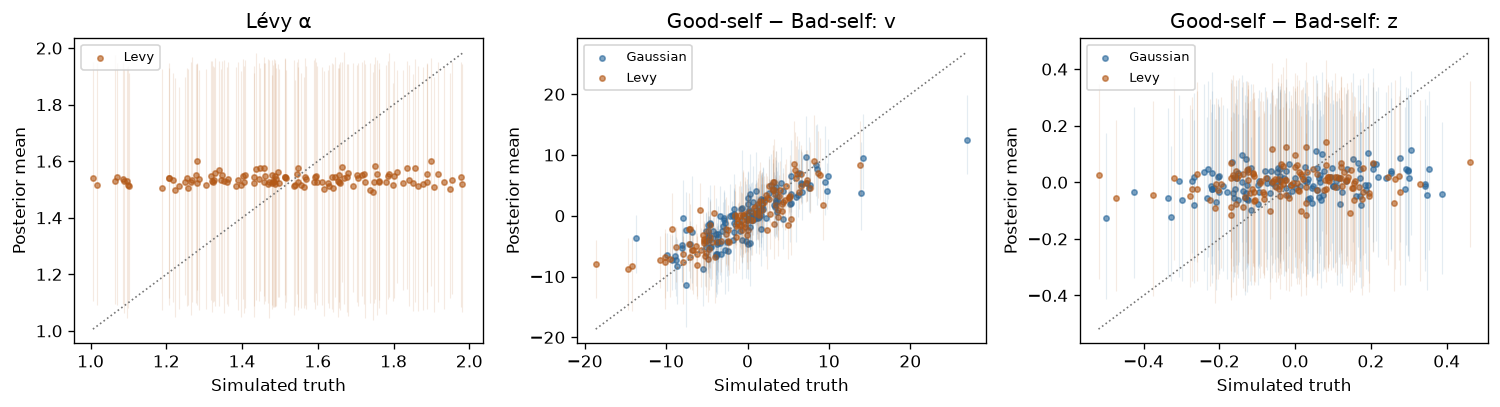

In [10]:
# 横轴为模拟真值，纵轴为后验均值，竖线为 95% 区间。
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.5))
model_styles = {"Gaussian": ("#29679b", "-"), "Levy": ("#b35917", "--")}
for ax, parameter, title in zip(
    axes, ["alpha", "delta_v", "delta_z"], ["Lévy α", "Good-self − Bad-self: v", "Good-self − Bad-self: z"],
):
    subset = recovery[recovery["parameter"].eq(parameter)]
    for name, values in subset.groupby("model", sort=False):
        colour, _ = model_styles[name]
        ax.vlines(values["truth"], values["low_95"], values["high_95"], color=colour, alpha=0.12, lw=0.7)
        ax.scatter(values["truth"], values["estimate"], color=colour, alpha=0.6, s=10, label=name)
    bounds = subset[["truth", "estimate", "low_95", "high_95"]].to_numpy()
    lower, upper = bounds.min(), bounds.max()
    ax.plot([lower, upper], [lower, upper], color="#777777", linestyle=":", lw=1)
    ax.set(title=title, xlabel="Simulated truth", ylabel="Posterior mean")
    ax.legend(fontsize=8)
show_figure(fig, "parameter_recovery")

### 5.3 小档与中档的配对比较

读取[已保存的小档基准表](../outputs/levy/individual_window_flow_check/parameter_recovery.csv)，逐项核对相同的模拟真值和先验均值。误差下降量为小档 MAE 减中档 MAE。

In [11]:
metrics = ["simulations", "mae", "coverage_95", "mean_width_95"]
recovery_keys = ["model", "parameter"]
pilot_summary = pd.read_csv(pilot_dir / "parameter_recovery.csv", usecols=recovery_keys + metrics)
budget_comparison = pilot_summary.merge(
    recovery_summary[recovery_keys + metrics], on=recovery_keys, how="outer", validate="one_to_one",
    suffixes=("_pilot", "_optimization"), indicator=True,
)
assert budget_comparison.pop("_merge").eq("both").all()
assert budget_comparison["simulations_pilot"].eq(budget_comparison["simulations_optimization"]).all()

# 逐条核对两次恢复检查使用了相同的模拟真值。
pair_keys = [*recovery_keys, "simulation"]
truth_columns = [*pair_keys, "truth", "prior_mean"]
pilot_truth = pd.read_csv(pilot_dir / "parameter_recovery_draw_summary.csv", usecols=truth_columns)
paired_truth = pilot_truth.merge(
    recovery[truth_columns], on=pair_keys, how="outer", validate="one_to_one",
    suffixes=("_pilot", "_optimization"), indicator=True,
)
assert paired_truth.pop("_merge").eq("both").all()
for name in ["truth", "prior_mean"]:
    np.testing.assert_allclose(paired_truth[f"{name}_pilot"], paired_truth[f"{name}_optimization"], rtol=1e-7, atol=1e-9)

# 差值为正表示中档的平均绝对误差降低。
budget_comparison["mae_improvement"] = budget_comparison["mae_pilot"] - budget_comparison["mae_optimization"]
save_table(budget_comparison, "parameter_recovery_budget_comparison")
# 屏幕上给出核心参数的误差和覆盖率，完整区间宽度也保存在 CSV。
comparison_columns = [
    "model", "parameter", "mae_pilot", "mae_optimization", "mae_improvement",
    "coverage_95_pilot", "coverage_95_optimization",
]
focus = budget_comparison["parameter"].isin(["alpha", "delta_v", "delta_z"])
display(budget_comparison.loc[focus, comparison_columns].round(4))

,model,parameter,mae_pilot,mae_optimization,mae_improvement,coverage_95_pilot,coverage_95_optimization
1,Gaussian,delta_v,2.4179,2.1823,0.2357,0.9453,0.9453
2,Gaussian,delta_z,0.1490,0.1445,0.0045,0.9141,0.9219
24,Levy,alpha,0.1990,0.1990,-0.0001,0.9297,0.9062
25,Levy,delta_v,1.9016,1.8170,0.0846,0.9453,0.9453
26,Levy,delta_z,0.1235,0.1236,-0.0001,0.9531,0.9531


## 6. 真人留出预测

### 6.1 个人后验和留出试次模拟

每位被试用自己的拟合试次估计参数。每个模型抽取 512 组后验参数，选取其中 100 组在留出设计上模拟。保存个人参数和拟合数据的模型辨别概率。

In [12]:
# 两个模型共享留出试次设计和个人窗口，按键与 RT 从各自的后验预测生成。
selected = np.linspace(0, empirical_draws - 1, predictive_draws, dtype=int)
n_subjects = len(subjects)
subject_index, trial_position = test_slots
design_columns = ["subj_idx", "condition", "shape", "match", "val", "id", "stim"]
network_deadlines = deadlines[:, None].astype("float32")
prediction_grid = np.tile(test_grid, (predictive_draws, 1))
prediction_deadlines = np.tile(deadlines, predictive_draws)
prediction_design = pd.concat([heldout_trials[design_columns]] * predictive_draws, ignore_index=True)

posterior_rows, predictions = [], {}
for name, code in models.items():
    rng = np.random.default_rng(seed + 200)
    scores = net.posterior(
        observed_rt, fit_grid, network_deadlines,
        code, empirical_draws, int(rng.integers(2**30)),
    )
    parameters = individual_parameters(scores, code)
    values = with_self_contrasts(parameters)
    lower, upper = np.quantile(values, [0.025, 0.975], axis=1)
    labels = parameter_names if code == 1 else [p for p in parameter_names if p != "alpha"]
    columns = [parameter_names.index(p) for p in labels]
    posterior_rows.append(pd.DataFrame({
        "model": name, "subj_idx": np.repeat(subjects.to_numpy(), len(labels)),
        "parameter": np.tile(labels, n_subjects), "mean": values[..., columns].mean(axis=1).ravel(),
        "low_95": lower[:, columns].ravel(), "high_95": upper[:, columns].ravel(),
    }))

    # 把抽样和被试排成一批，模拟后再按原留出表的行序取回预测值。
    chosen = parameters[:, selected, :].transpose(1, 0, 2).reshape(predictive_draws * n_subjects, -1)
    seeds = rng.integers(2**32, size=len(prediction_deadlines), dtype=np.uint32)
    signed_grid = simulate_signed_rt(chosen, prediction_grid, seeds, prediction_deadlines, dt)
    signed_grid = signed_grid.reshape(predictive_draws, n_subjects, -1)
    signed = signed_grid[:, subject_index, trial_position]
    predictions[name] = prediction_design.assign(
        rt=np.abs(signed).ravel(),
        response=(signed > 0).ravel().astype("int8"),
    )

# 每行是一个人的后验概要。形状差值来自该人的同次抽样。
participant_posterior = pd.concat(posterior_rows, ignore_index=True)
save_table(participant_posterior, "participant_posterior")
probabilities = net.model_probabilities(observed_rt, fit_grid, network_deadlines)
probability_table = pd.DataFrame({
    "subj_idx": subjects, "p_gaussian": probabilities[:, 0], "p_levy": probabilities[:, 1],
})
save_table(probability_table, "participant_model_probabilities")
display(probability_table.head().round(3))

,subj_idx,p_gaussian,p_levy
0,7304,0.317,0.683
1,7305,0.375,0.625
2,7306,0.497,0.503
3,7307,0.398,0.602
4,7308,0.437,0.563


### 6.2 联合评分与逐人比较

对同一位被试、同一个刺激条件下的真实按键和反应时计算联合对数预测密度（LPD）。同批留出数据得分越高，说明模型给实际作答的联合密度越高。总体均分和逐人分差分别保存。

In [13]:
# 每个被试条件的带宽尺度取自拟合数据。不同模型共用带宽规则。
strata = ["subj_idx", "condition"]
fit_scale = training_trials.assign(log_rt=np.log(training_trials["rt"])).groupby(strata)["log_rt"].std()
deadline_by_subject = pd.Series(deadlines, index=subjects)
heldout_cells = heldout_trials.groupby(strata)


def joint_log_score(simulation):
    """在有截止窗口内，为每条真实留出按键与 RT 计算其联合对数密度。"""
    simulated_cells = simulation.groupby(strata)
    scores = pd.Series(index=heldout_trials.index, dtype=float)
    lower = np.log(t_limits[0] + dt)
    for key, actual in heldout_cells:
        sample = simulated_cells.get_group(key)
        simulated_rt = np.log(sample["rt"].to_numpy())
        actual_rt = np.log(actual["rt"].to_numpy())
        upper = np.log(deadline_by_subject.at[key[0]])
        n_simulated = len(sample)
        bandwidth = fit_scale.loc[key] * n_simulated ** (-0.2)

        # 用允许的 log RT 区间内的概率质量归一化每个核。
        kernel_mass = ndtr((upper - simulated_rt) / bandwidth) - ndtr((lower - simulated_rt) / bandwidth)
        distance = (actual_rt[:, None] - simulated_rt) / bandwidth
        log_kernel = -0.5 * distance**2 - np.log(kernel_mass)
        same_choice = actual["response"].to_numpy()[:, None] == sample["response"].to_numpy()

        # 同一按键的预测进入分子，全条件的预测进入分母。`−log(RT)` 将密度换回每秒。
        density = logsumexp(np.where(same_choice, log_kernel, -np.inf), axis=1)
        density -= np.log(n_simulated * bandwidth * np.sqrt(2 * np.pi)) + actual_rt
        scores.loc[actual.index] = np.where((actual_rt >= lower) & (actual_rt <= upper), density, -np.inf)
    return scores


pointwise = heldout_trials[[*strata, "rt", "response"]].copy()
for name, simulation in predictions.items():
    pointwise[name] = joint_log_score(simulation)
pointwise["levy_minus_gaussian"] = pointwise["Levy"] - pointwise["Gaussian"]

# 保留零密度试次；若两种模型都给零密度，则该试次或对应被试的差值未定义。
scores_by_person = []
for subject, rows in pointwise.groupby("subj_idx"):
    means = rows[["Gaussian", "Levy"]].to_numpy().mean(axis=0)
    scores_by_person.append({
        "subj_idx": subject, "heldout_trials": len(rows),
        "gaussian_mean_lpd": means[0], "levy_mean_lpd": means[1],
        "levy_minus_gaussian": means[1] - means[0], "gaussian_zero_density": np.isneginf(rows["Gaussian"]).sum(),
        "levy_zero_density": np.isneginf(rows["Levy"]).sum(),
    })
by_subject = pd.DataFrame(scores_by_person)
overall_scores = pd.DataFrame([
    {"model": name, "heldout_trials": len(pointwise), "total_lpd": pointwise[name].to_numpy().sum(),
     "mean_lpd": pointwise[name].to_numpy().mean(), "zero_density_trials": np.isneginf(pointwise[name]).sum()}
    for name in models
])
save_table(pointwise, "heldout_joint_lpd_by_trial")
save_table(by_subject, "heldout_joint_lpd_by_subject")
save_table(overall_scores, "heldout_joint_lpd")
display(overall_scores.round(3))

# 补充逐被试方向，避免总体均分掩盖个体间的分差。
difference = by_subject["levy_minus_gaussian"]
display(pd.Series({
    "Levy higher": int(difference.gt(0).sum()),
    "Gaussian higher": int(difference.lt(0).sum()),
    "Tied": int(difference.eq(0).sum()),
    "Undefined": int(difference.isna().sum()),
}, name="Participants"))

,model,heldout_trials,total_lpd,mean_lpd,zero_density_trials
0,Gaussian,4929,-672.108,-0.136,0
1,Levy,4929,397.844,0.081,0


,Participants
Levy higher,19
Gaussian higher,23
Tied,0
Undefined,0


### 6.3 慢反应 P90、Match 选择率与密度图

P90 分刺激和实际按键汇总，共 16 格。Match 选择率按八个刺激条件汇总。密度图的同一刺激下两个按键共享分母，曲线面积体现相应按键的比例。

In [14]:
# 按真实刺激与实际选择汇总慢反应，选 Match 的比例使用该条件下所有有效反应。
sources = {"Observed": heldout_trials, **predictions}
by_choice = ["condition", "response"]
p90_ms = pd.DataFrame({
    name: 1000 * data.groupby(by_choice)["rt"].quantile(0.90) for name, data in sources.items()
})
match_rate = pd.DataFrame({
    name: data.groupby("condition")["response"].mean() for name, data in sources.items()
})
prediction_errors = pd.DataFrame([
    {"model": name, "p90_mae_ms": (p90_ms[name] - p90_ms["Observed"]).abs().mean(skipna=False),
     "match_mae_pp": 100 * (match_rate[name] - match_rate["Observed"]).abs().mean(skipna=False)}
    for name in models
])
save_table(p90_ms.reset_index(), "heldout_rt_p90")
save_table(match_rate.reset_index(), "heldout_choice_rates")
save_table(prediction_errors, "heldout_errors")
display(prediction_errors.round(2))

,model,p90_mae_ms,match_mae_pp
0,Gaussian,96.28,6.76
1,Levy,85.73,4.24


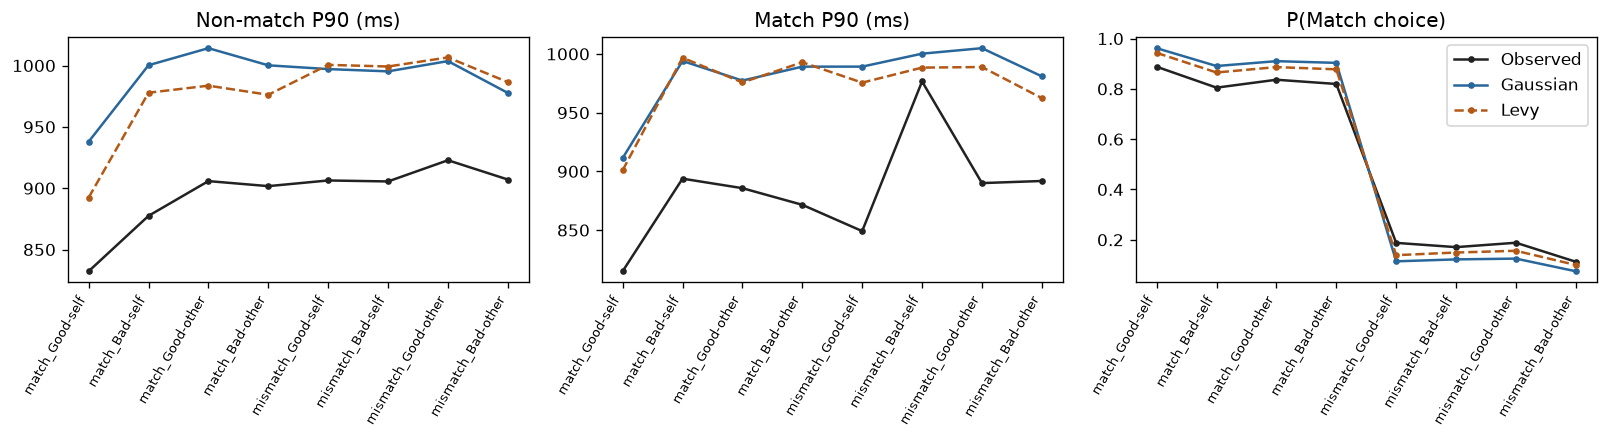

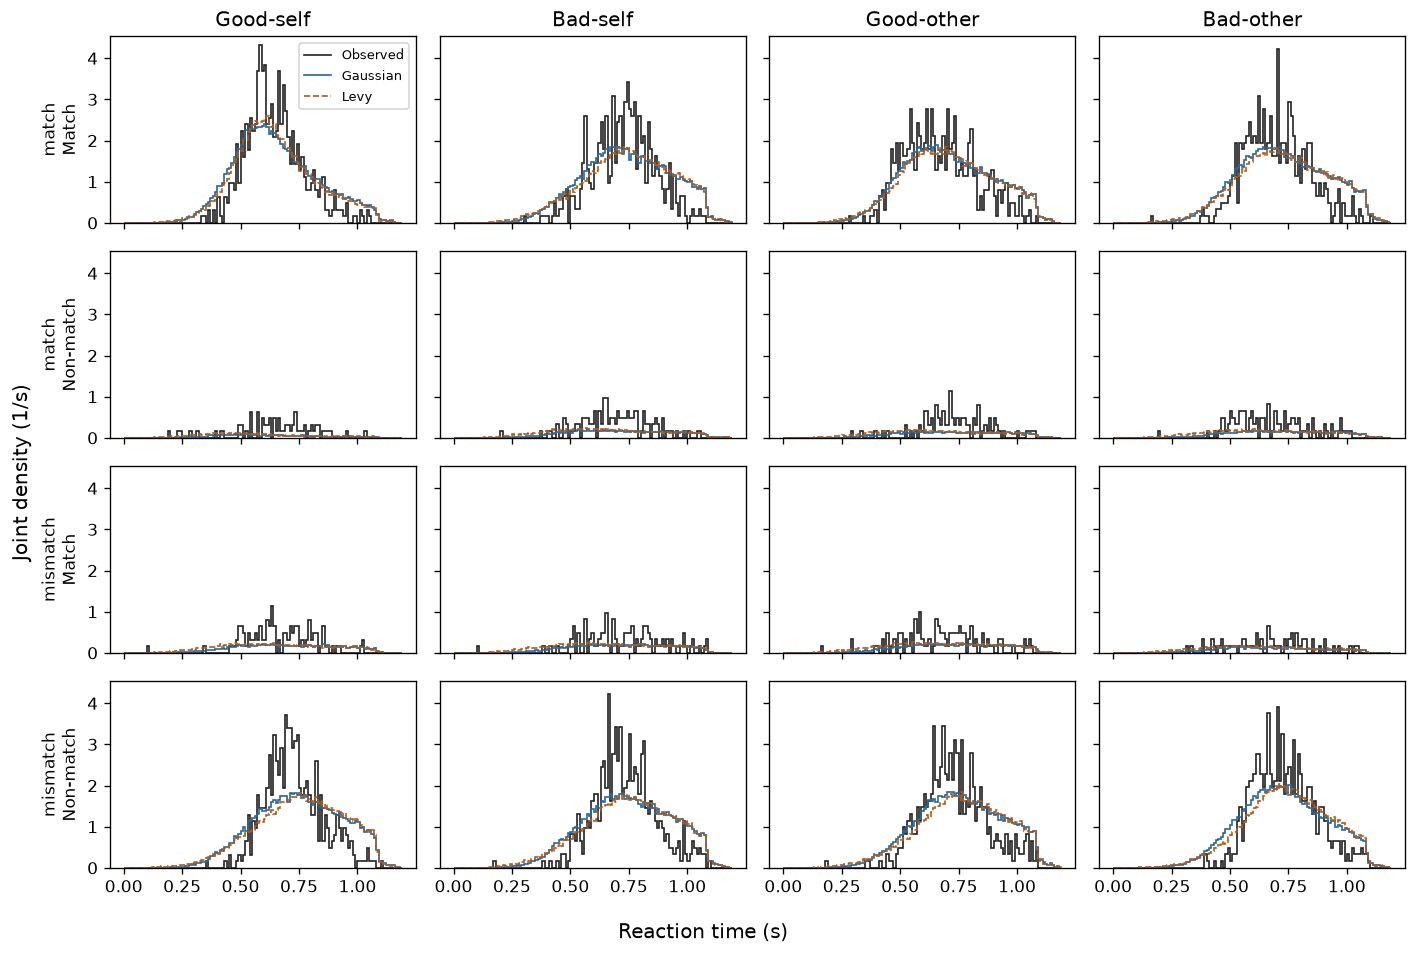

In [15]:
# 三栏依次画 Non-match P90、Match P90 和 Match 选择率。
styles = {"Observed": ("#222222", "-"), **model_styles}
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for name, (colour, line) in styles.items():
    panels = [
        p90_ms[name].xs(0, level="response"),
        p90_ms[name].xs(1, level="response"),
        match_rate[name],
    ]
    for ax, values in zip(axes, panels):
        ax.plot(range(len(conditions)), values.reindex(conditions), color=colour, ls=line, marker=".", label=name)
for ax, title in zip(axes, ["Non-match P90 (ms)", "Match P90 (ms)", "P(Match choice)"]):
    ax.set(title=title, xticks=range(len(conditions)))
    ax.set_xticklabels(conditions, rotation=60, ha="right", fontsize=8)
axes[-1].legend()
show_figure(fig, "heldout_slow_rt_and_choice")

# 纵轴为选择与 RT 的联合密度。同一刺激下两种选择共用归一化分母。
# 每个箱宽 0.010 秒（10 ms），最后一个箱覆盖最长作答窗口。
plot_bin_width = 0.010
bins = np.arange(int(np.ceil(deadlines.max() / plot_bin_width)) + 1) * plot_bin_width
fig, axes = plt.subplots(4, 4, figsize=(12, 8), sharex=True, sharey=True)
panel_rows = [("match", 1), ("match", 0), ("mismatch", 1), ("mismatch", 0)]
for j, shape in enumerate(shapes):
    axes[0, j].set_title(shape)
    for i, (stimulus, choice) in enumerate(panel_rows):
        ax = axes[i, j]
        for name, data in sources.items():
            cell = data[data["shape"].eq(shape) & data["match"].eq(stimulus)]
            selected_rt = cell.loc[cell["response"].eq(choice), "rt"]
            bins_count = np.histogram(selected_rt, bins=bins)[0]
            density = bins_count / (len(cell) * np.diff(bins))
            colour, line = styles[name]
            ax.stairs(density, bins, color=colour, ls=line, label=name)
        if j == 0:
            actual_choice = "Match" if choice == 1 else "Non-match"
            ax.set_ylabel(f"{stimulus}\n{actual_choice}")
axes[0, 0].legend(fontsize=8)
fig.supxlabel("Reaction time (s)")
fig.supylabel("Joint density (1/s)")
show_figure(fig, "heldout_rt_choice_density")